In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl

%matplotlib inline

wgpu version from git (0.15.3) and __version__ (0.19.3) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.7.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post104+g63d70c0, need >=(0, 19, 0), <(0, 20, 0).
    To update, use e.g. `pip install -U wgpu`.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
np.random.choice([0.7, 0.55, 0.75])

np.float64(0.55)

In [4]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: int,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg = 0,
        firing_prop = 0.05,
        interp_factor: int = 2,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: int

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor)) + 0.01
    # print(clean)

    x = 0
    a_options = [0.7, 0.6, 0.55]
    a_decay = 0.7
    a_rise = 5

    (0.01 / 5) * (5 / 0.01) * 5

    b = 0

    n_rise = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(bool))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            if spikes[c_ix][i]:
                a = a_rise
                a_decay = np.random.choice(a_options)
                n_rise = 5
            elif n_rise > 0:
                if clean[c_ix, i - 1] > 1:
                    a = a_decay
                    n_rise = 0
                else:
                    a = a_rise
                    n_rise -= 1
            else:
                a = a_decay
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2])# + (1 * spikes[c_ix][i])

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

In [5]:
n_components = 1

In [433]:
np.random.seed(0)
X, _ = generate_data(
    n_timepoints=250,
    n_components=n_components,
    noise=0.01,
    n_pixels=1,
    n_pixels_bg=0,
    interp_factor=2,
    firing_prop=0.05,
)

In [434]:
X.shape

(1, 500)

In [435]:
X = X[:]# 230:300]

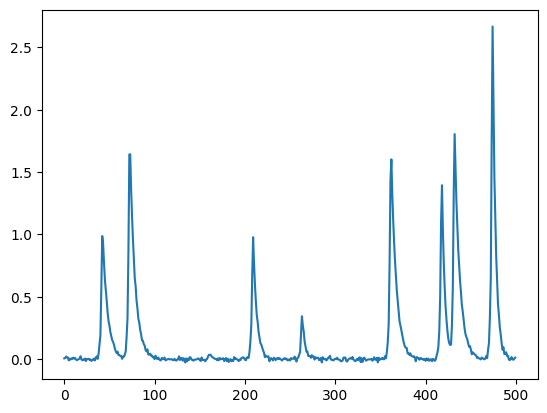

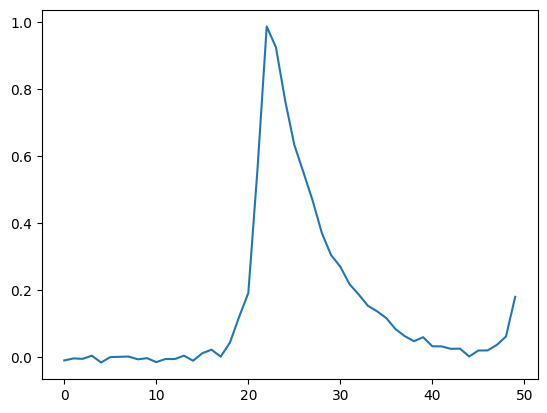

In [441]:
plt.plot(X[0])
# plt.plot(X[1])
plt.show()
plt.plot(X.ravel()[20:70])

In [442]:
lag = 2

H = scipy.linalg.hankel(X[0, :lag * 2], X[0, lag * 2 - 1:])

<Axes: >

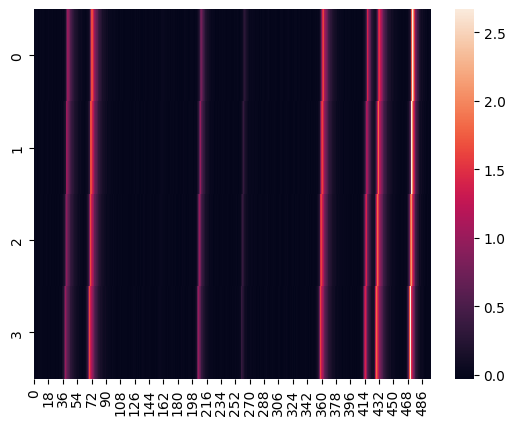

In [443]:
sns.heatmap(H)

<Axes: >

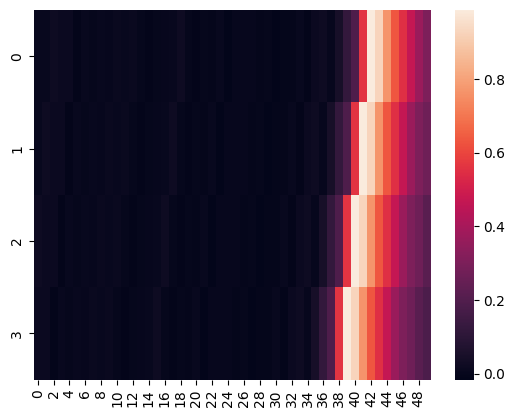

In [444]:
sns.heatmap(H[:, :50])

In [445]:
mu0 = np.mean(H[:2])
mu1 = np.mean(H[2:])

In [446]:
H[:2] -= mu0
H[2:] -= mu1

In [447]:
cov = (H @ H.T) / H.shape[1]

<Axes: >

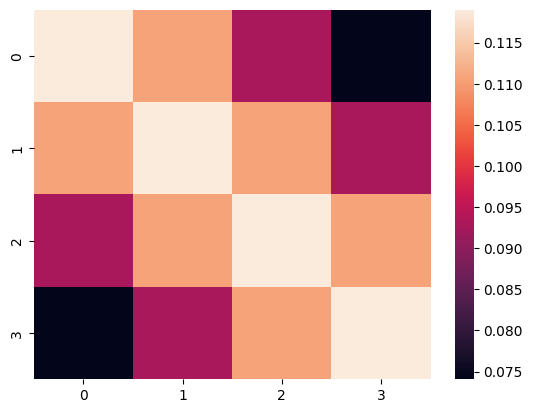

In [448]:
sns.heatmap(cov)

In [449]:
cov

array([[0.11898364, 0.11058067, 0.09269991, 0.07406662],
       [0.11058067, 0.11899042, 0.110585  , 0.0927055 ],
       [0.09269991, 0.110585  , 0.11899246, 0.11058842],
       [0.07406662, 0.0927055 , 0.11058842, 0.11899704]])

In [450]:
past = H[:2]
future = H[2:]

In [451]:
past.shape

(2, 497)

In [452]:
PP = past @ past.T / past.shape[1]
FF = future @ future.T / future.shape[1]
PF = past @ future.T / past.shape[1]

<Axes: >

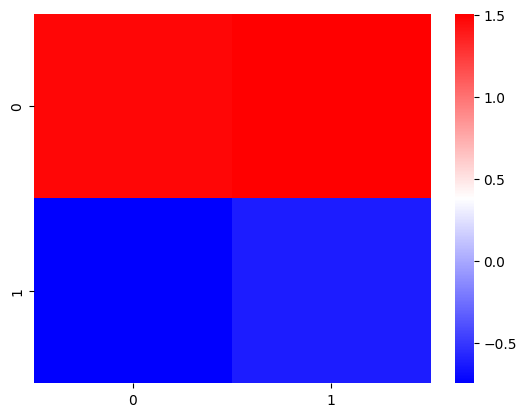

In [453]:
sns.heatmap(np.linalg.inv(FF) @ (future @ past.T / past.shape[1]), cmap="bwr")

In [454]:
from deeptime.numeric import spd_inv_sqrt

In [455]:
PP_inv_sqrt = linalg.inv(linalg.sqrtm(PP))
FF_inv_sqrt = linalg.inv(linalg.sqrtm(FF))

K_bar = PP_inv_sqrt @ PF @ FF_inv_sqrt

In [456]:
U, S, Vh = np.linalg.svd(K_bar,full_matrices=False)

# mapping data to the left and right sigular vectors
left_vec = PP_inv_sqrt @ U
right_vec = FF_inv_sqrt @ Vh.T

# projection of data onto left and right singular vectors
# proj_left = past.T @ left_vec
# proj_right = future.T @ right_vec

proj_left = left_vec.T @ past
proj_right = right_vec.T @ future

Text(0.5, 1.0, 'right')

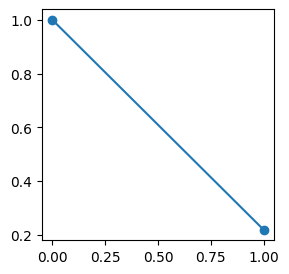

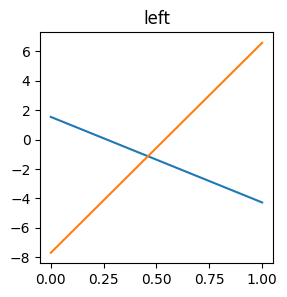

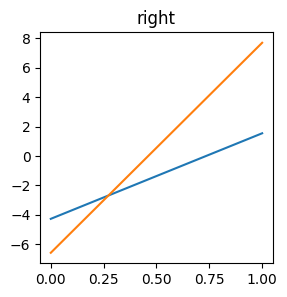

In [457]:
plt.figure(figsize=(3, 3))
plt.plot(S / S.max(),'o-')

plt.figure(figsize=(3, 3))
plt.plot(left_vec)
plt.title("left")

plt.figure(figsize=(3, 3))
plt.plot(right_vec)
plt.title("right")

In [458]:
X.ravel().shape

(500,)

Text(0.5, 1.0, 'proj left, past')

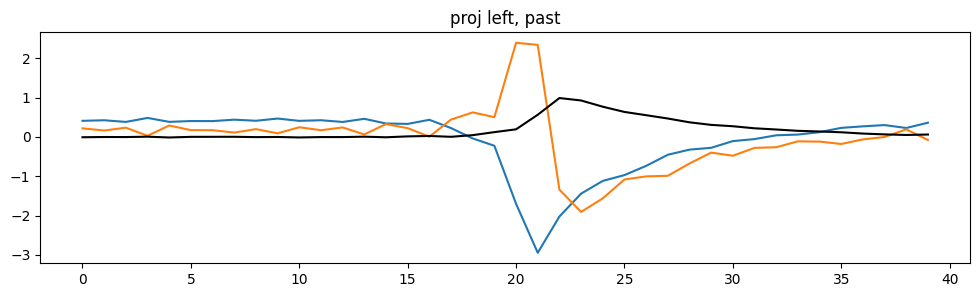

In [459]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_left.T[20:60])
plt.plot(X.ravel()[20:60], c="k")
plt.title("proj left, past")

Text(0.5, 1.0, 'proj right, future')

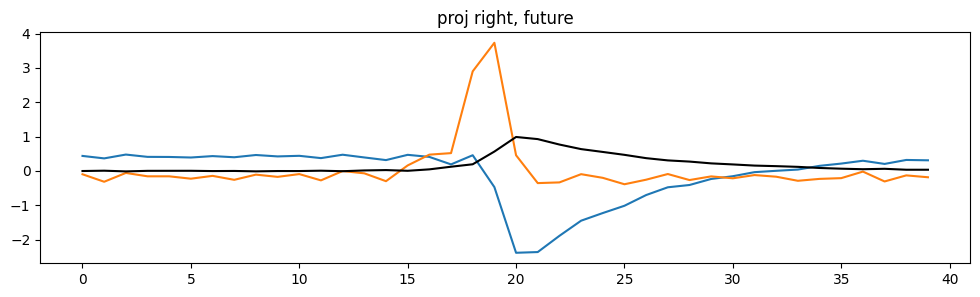

In [460]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_right.T[20:60])
plt.plot(X.ravel()[20+lag:60+lag], c="k")
plt.title("proj right, future")

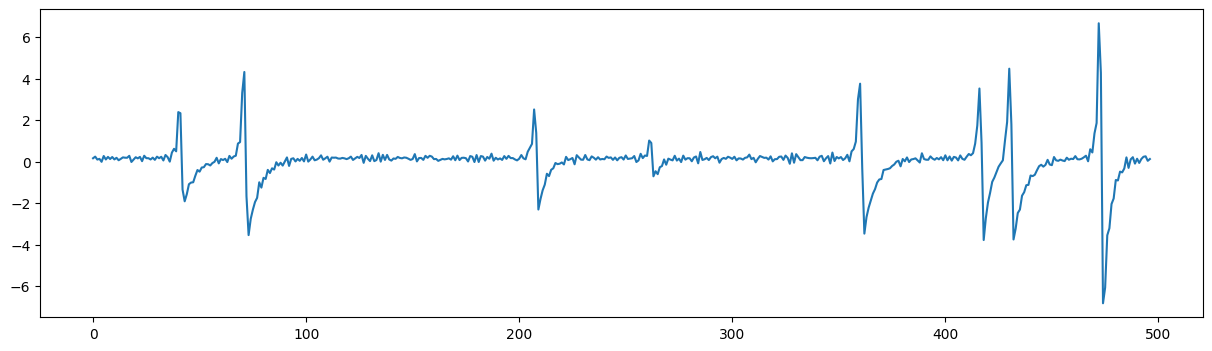

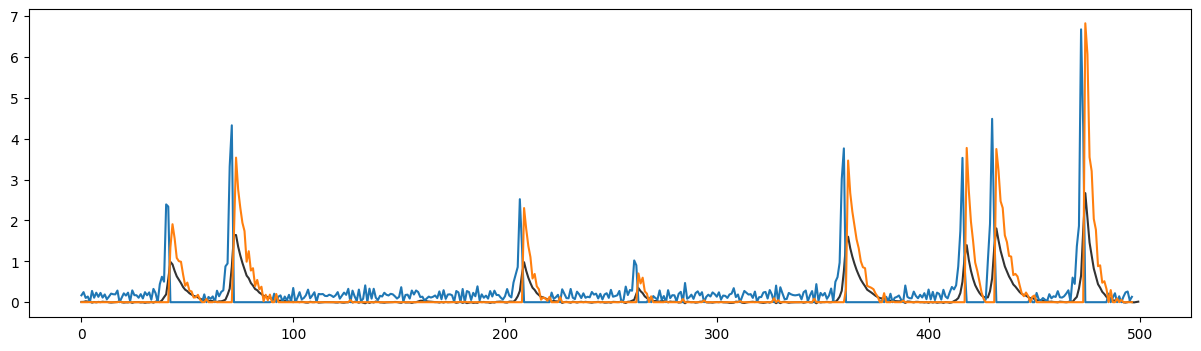

In [464]:
fig = plt.figure(figsize=(15, 4))
plt.plot(proj_left.T[:, 1])
plt.show()

fig = plt.figure(figsize=(15, 4))
r1 = proj_left.T[:, 1].copy()
r1[r1 < 0] = 0

r2 = proj_left.T[:, 1].copy()
r2[r2 > 0] = 0
r2 = np.abs(r2)

plt.plot(X.ravel(), c="k", alpha=0.8)
plt.plot(r1)
plt.plot(r2)

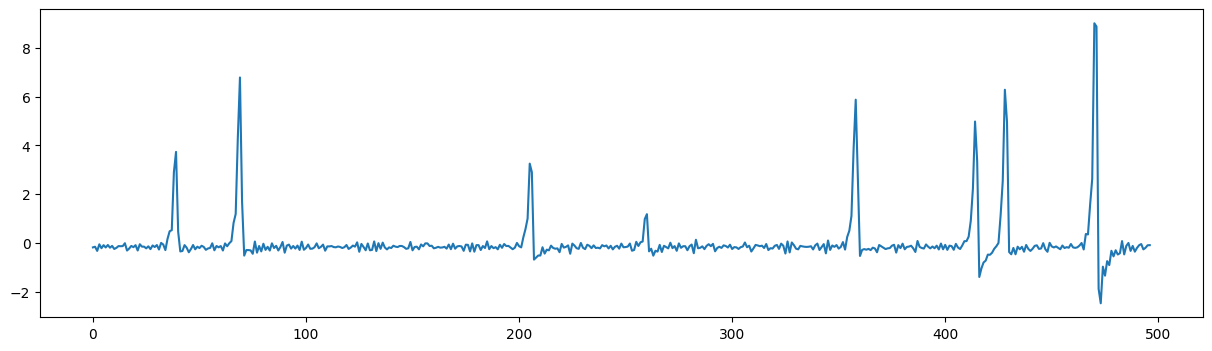

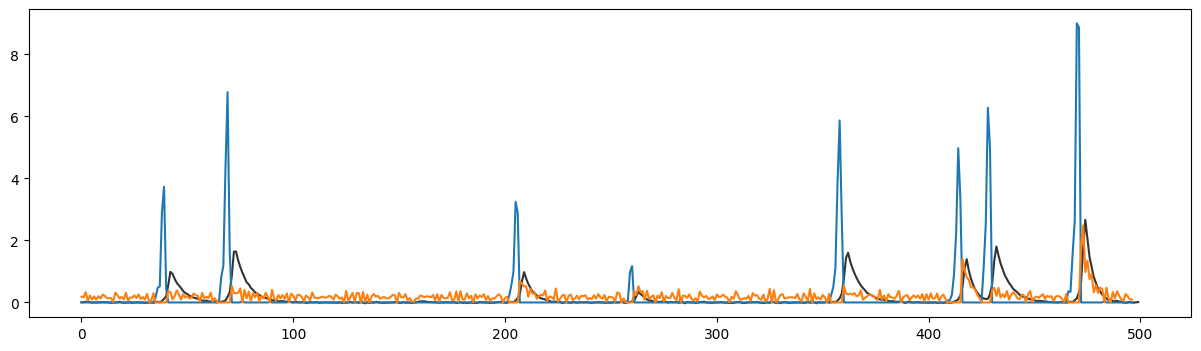

In [465]:
fig = plt.figure(figsize=(15, 4))
plt.plot(proj_right.T[:, 1])
plt.show()

fig = plt.figure(figsize=(15, 4))
r1 = proj_right.T[:, 1].copy()
r1[r1 < 0] = 0

r2 = proj_right.T[:, 1].copy()
r2[r2 > 0] = 0
r2 = np.abs(r2)

plt.plot(X.ravel(), c="k", alpha=0.8)
plt.plot(r1)
plt.plot(r2)

In [ ]:
fig = plt.figure(figsize=(15, 4))
plt.plot(proj_left.T[:, 1])
plt.show()

fig = plt.figure(figsize=(15, 4))
r1 = proj_left.T[:, 1].copy()
r1[r1 < 0] = 0

r2 = proj_left.T[:, 1].copy()
r2[r2 > 0] = 0
r2 = np.abs(r2)

plt.plot(X.ravel(), c="k", alpha=0.8)
plt.plot(r1)
plt.plot(r2)

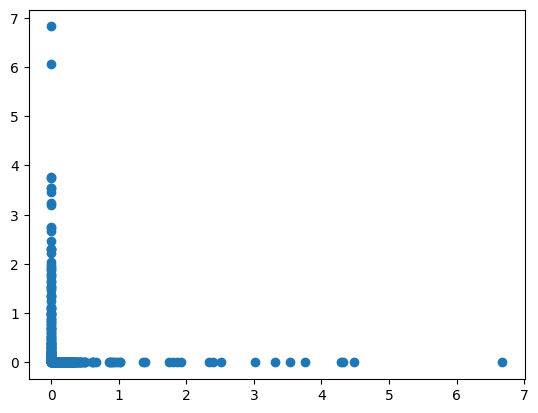

In [462]:
plt.scatter(r1, r2)

<Axes: >

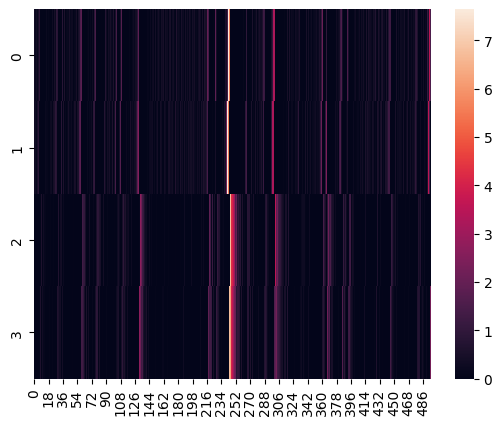

In [402]:
lag = 2

r1_ = scipy.linalg.hankel(r1[:lag], r1[lag - 1:])
r2_ = scipy.linalg.hankel(r2[:lag], r2[lag - 1:])

A = np.vstack([r1_, r2_])
sns.heatmap(A)

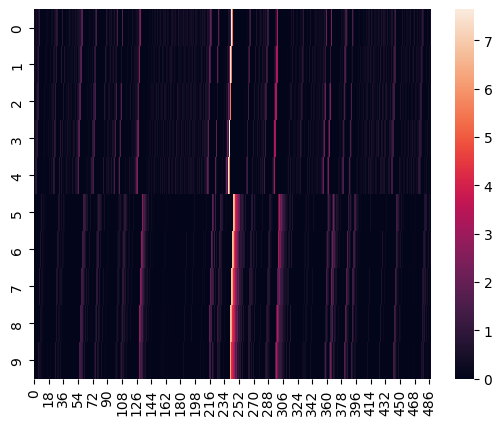

<Axes: >

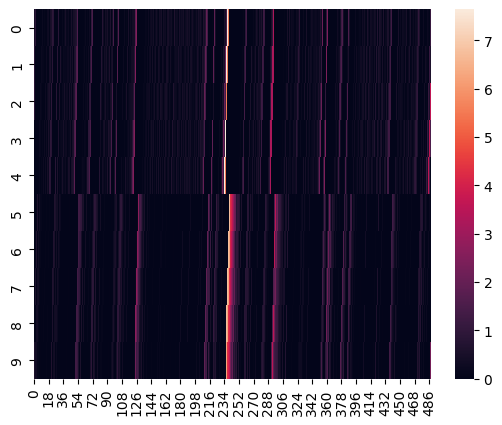

In [403]:
lag = 5

r1_ = scipy.linalg.hankel(r1[:lag * 2], r1[lag * 2 - 1:])
r2_ = scipy.linalg.hankel(r2[:lag * 2], r2[lag * 2 - 1:])

A = np.vstack([r1_[:lag], r2_[:lag]])
B = np.vstack([r1_[lag:], r2_[lag:]])

sns.heatmap(A)
plt.show()

sns.heatmap(B)

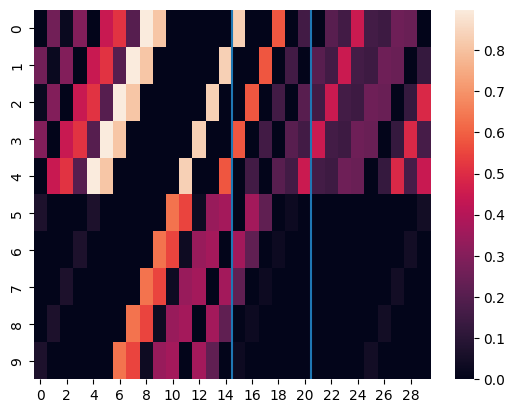

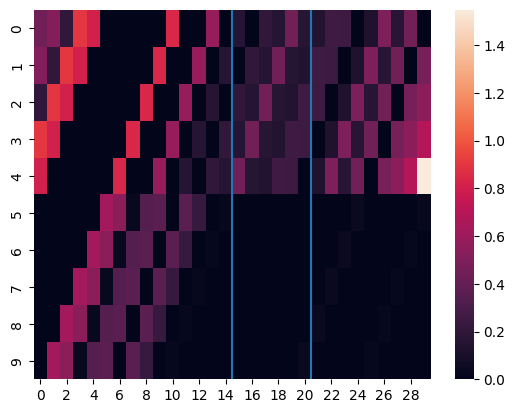

In [404]:
ax = sns.heatmap(A[:, 20:50])
ax.vlines(21, ymin=0, ymax=lag*10)
ax.vlines(15, ymin=0, ymax=lag*10)
plt.show()

ax = sns.heatmap(B[:, 20:50])
ax.vlines(15, ymin=0, ymax=lag*10)
ax.vlines(21, ymin=0, ymax=lag*10)

In [405]:
A -= A.mean()
B -= B.mean()

In [406]:
AA = A @ A.T / A.shape[1]
BB = B @ B.T / B.shape[1]
AB = A @ B.T / A.shape[1]

In [407]:
AA_inv_sqrt = linalg.inv(linalg.sqrtm(AA))
BB_inv_sqrt = linalg.inv(linalg.sqrtm(BB))

K_bar2 = AA_inv_sqrt @ AB @ BB_inv_sqrt

In [408]:
U2, S2, Vh2 = np.linalg.svd(K_bar2,full_matrices=False)

# mapping data to the left and right sigular vectors
left_vec2 = AA_inv_sqrt @ U2
right_vec2 = BB_inv_sqrt @ Vh2.T

proj_left2 = left_vec2.T @ A
proj_right2 = right_vec2.T @ B

Text(0.5, 1.0, 'right')

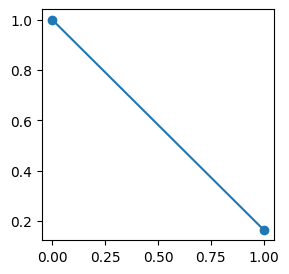

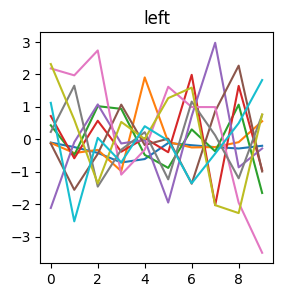

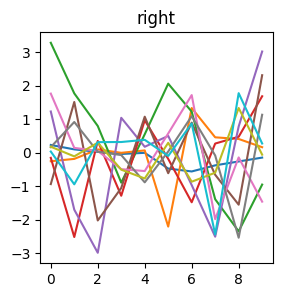

In [409]:
plt.figure(figsize=(3, 3))
plt.plot(S / S.max(),'o-')

plt.figure(figsize=(3, 3))
plt.plot(left_vec2)
plt.title("left")

plt.figure(figsize=(3, 3))
plt.plot(right_vec2)
plt.title("right")

Text(0.5, 1.0, 'proj2 left')

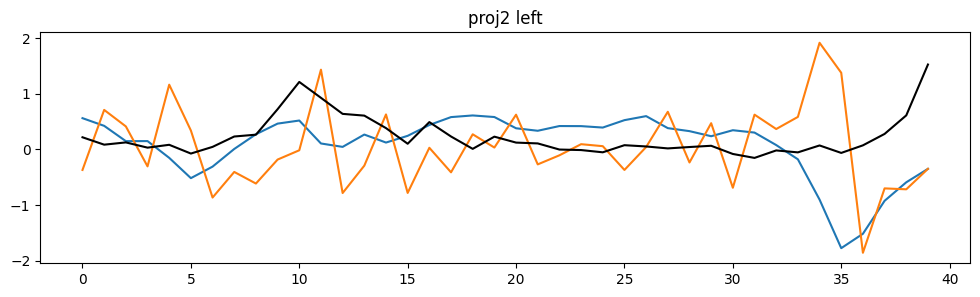

In [410]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_left2[:2].T[20:60])
plt.plot(X.ravel()[20:60], c="k")
plt.title("proj2 left")

Text(0.5, 1.0, 'proj2 right')

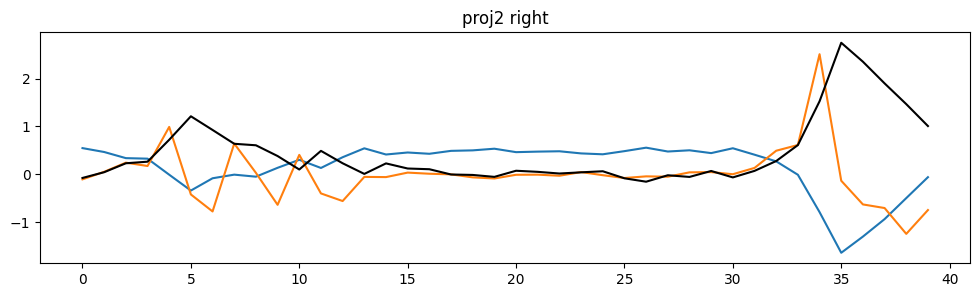

In [411]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_right2[:2].T[20:60])
plt.plot(X.ravel()[20+lag:60+lag], c="k")
plt.title("proj2 right")

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
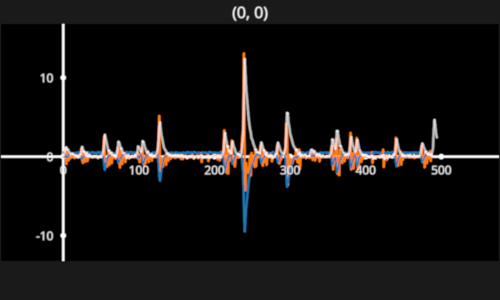

In [412]:
fig = fpl.Figure()

fig[0, 0].add_line_collection(proj_right2[:2], cmap="tab10", alpha=0.8)
fig[0, 0].add_line(X.ravel()[lag:], alpha=0.5)

fig[0, 0].axes.intersection = (0, 0, 0)

fig.show(maintain_aspect=False)

In [413]:
proj_left2.shape

(10, 488)

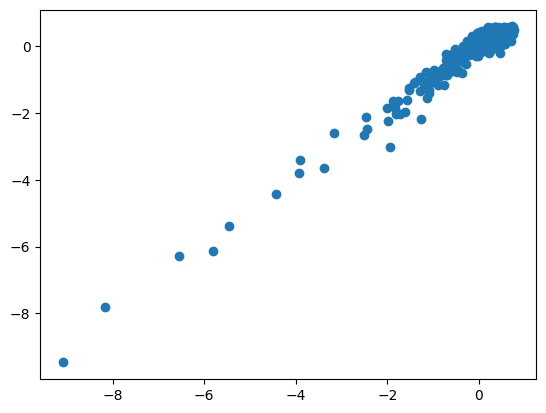

In [414]:
plt.scatter(proj_left2[0], proj_right2[0])

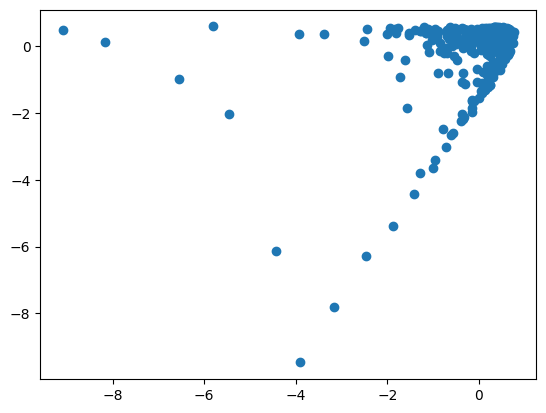

In [415]:
plt.scatter(proj_left2[0, lag:], proj_right2[0, :-lag])

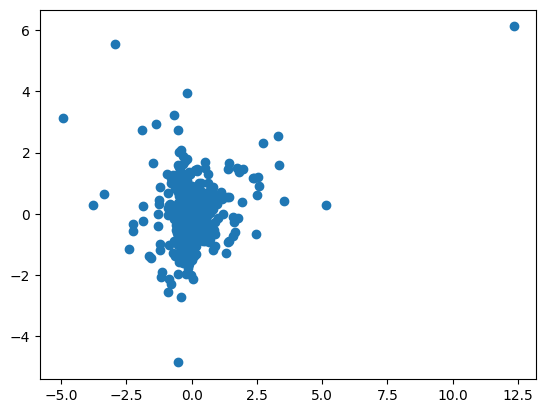

In [416]:
plt.scatter(proj_left2[1, lag:], proj_right2[2, :-lag])

In [34]:
X.shape

(1, 500)

In [35]:
proj_left.shape

(2, 497)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
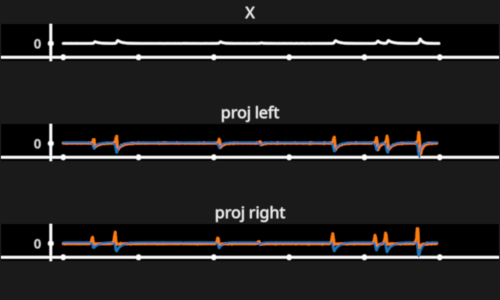

In [36]:
fig2 = fpl.Figure((3, 1), names=[["X", "proj left", "proj right"]], controller_ids="sync")

fig2["X"].add_line(X.ravel())
fig2["proj left"].add_line_collection(proj_left, cmap="tab10")
fig2["proj right"].add_line_collection(proj_right, cmap="tab10")

fig2.show(maintain_aspect=False)

In [37]:
proj_not = np.abs(proj_left[0]) * np.abs(proj_left[1])
# proj_not = proj_not.max() - proj_not

RFBOutputContext()

/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:263: RuntimeWarning: divide by zero encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:263: RuntimeWarning: invalid value encountered in divide
  screen_full = (ndc_full[:, :2] / ndc_full[:, 3:4]) * half_canvas_size
/home/kushal/repos/pygfx/pygfx/objects/_ruler.py:275: RuntimeWarning: invalid value encountered in divide
  screen_sel = (ndc_sel[:, :2] / ndc_sel[:, 3:4]) * half_canvas_size


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
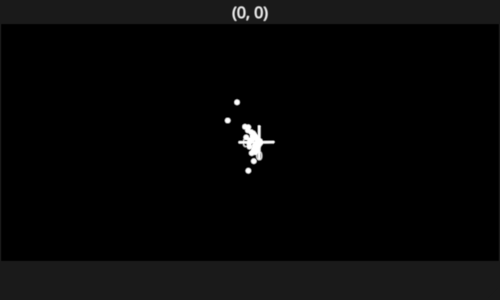

In [39]:
fig = fpl.Figure(cameras="3d", controller_types="orbit")

fig[0, 0].add_scatter(np.column_stack([proj_left.Tp:, 1]), sizes=5)
fig.show()

In [554]:
from sklearn.cluster import KMeans, SpectralClustering, AgglomerativeClustering, AffinityPropagation
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [555]:
from sklearn.metrics import pairwise_distances

In [556]:
scaler = StandardScaler()

In [557]:
proj_cov = (scaler.fit_transform(proj_left.T) @ scaler.fit_transform(proj_right.T).T) / proj_left.shape[1]

<Axes: >

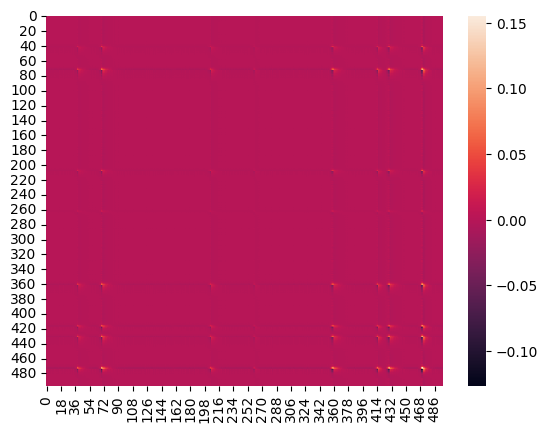

In [558]:
sns.heatmap(proj_cov)

In [559]:
proj_cov.shape

(497, 497)

In [560]:
proj_left.shape

(2, 497)

In [561]:
B = (proj_cov + proj_cov.T) / 2

In [562]:
km = KMeans(3)

km.fit(proj_left.T)

labels = km.labels_

In [563]:
fig3 = fpl.Figure(size=(1800, 600))

# fig3[0, 0].add_line(X_clean.ravel()[:-3], colors="red", alpha=0.5)
lg = fig3[0, 0].add_line(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-3]]), cmap="tab10", cmap_transform=labels)
lg_s = fig3[0, 0].add_scatter(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-3]]), sizes=7, cmap="tab10", cmap_transform=labels)

fig4 = fpl.Figure((1, 3), names=["left", "right", "Q"])

sg_left = fig4[0, 0].add_scatter(proj_left.T, sizes=7, cmap="tab10", cmap_transform=labels)
sg_right = fig4[0, 1].add_scatter(proj_right.T, sizes=7, cmap="tab10", cmap_transform=labels)

# fig5 = fpl.Figure(cameras="3d", controller_types="orbit")

# sg_Q = fig5[0, 0].add_scatter(Qk, sizes=5, cmap="tab10", cmap_transform=labels)

for subplot in fig4:
    subplot.axes.intersection = (0, 0, 0)

selector = lg.add_linear_selector()

@selector.add_event_handler("selection")
def set_point(ev):
    ix = ev.get_selected_index()
    sg_left.cmap = "tab10"
    sg_right.cmap = "tab10"
    sg_Q.cmap = "tab10"

    sg_left.colors[ix] = "w"
    sg_right.colors[ix] = "w"
    sg_Q.colors[ix] = "w"

def scatter_click_handler(ev):
    ix = ev.pick_info["vertex_index"]

    sg_left.cmap = "tab10"
    sg_right.cmap = "tab10"
    sg_Q.cmap = "tab10"

    sg_left.colors[ix] = "w"
    sg_right.colors[ix] = "w"
    sg_Q.colors[ix] = "w"
    
    selector.selection = ix

sg_left.add_event_handler(scatter_click_handler, "click")
sg_right.add_event_handler(scatter_click_handler, "click")

VBox([fig3.show(maintain_aspect=False), fig4.show()])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

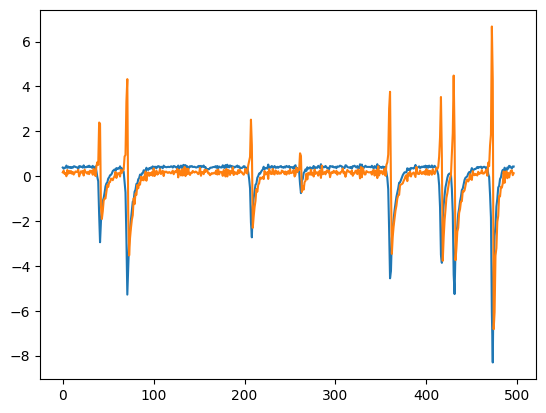

In [564]:
plt.plot(proj_left.T)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
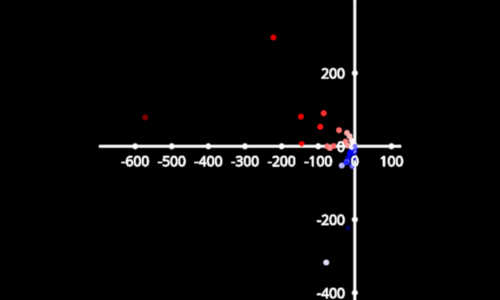

In [565]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

fig = fpl.Figure()
fig[0, 0].axes.intersection = (0, 0, 0)
fig[0, 0].add_scatter(proj_left.T ** 3, cmap="seismic", cmap_transform=(np.gradient(X.ravel()[:-3])), sizes=5)
fig.show()

In [566]:
from sklearn.preprocessing import PowerTransformer

In [567]:
scaled = PowerTransformer().fit_transform(proj_left.T)
fig[0, 0].graphics[0].data[:, :-1] = scaled

In [568]:
from sklearn.preprocessing import MinMaxScaler

In [569]:
agg = AgglomerativeClustering(3, metric="l1", linkage="complete")
agg.fit(MinMaxScaler().fit_transform(proj_left.T))
labels = agg.labels_

lg.cmap = "tab10"
lg.cmap.transform = labels
lg_s.cmap.transform = labels
lg_s.cmap = "tab10"

sg_left.cmap.transform = labels
sg_left.cmap = "tab10"
sg_right.cmap.transform = labels
sg_right.cmap = "tab10"

In [570]:
from deeptime.basis import Monomials

In [571]:
Y = Monomials(p=2, d=2)(H[:2].T)

mu0 = np.mean(Y[:-lag,:])
mu1 = np.mean(Y[lag:,:])
Past = Y[:-lag,:]
Future = Y[lag:,:]

# covariance matrices
C00 = (Past - mu0).T@(Past - mu0)/(Past.shape[0] - 1)
C11 = (Future - mu1).T@(Future - mu1)/(Future.shape[0] - 1)
C01 = (Past - mu0).T@(Future - mu1)/(Past.shape[0] - 1)
C00_half = linalg.sqrtm(C00)
C11_half = linalg.sqrtm(C11)

K = np.linalg.pinv(C00)@C01

# half-weighted koopman
Kbar = np.linalg.pinv(C00_half)@C01@np.linalg.pinv(C11_half)
# SVD 
U, S, Vh = np.linalg.svd(Kbar,full_matrices=False)

# mapping data to the left and right sigular vectors
left_vec = np.linalg.pinv(C00_half)@U
right_vec = np.linalg.pinv(C11_half)@Vh.T

# projection of data onto left and right singular vectors
proj_left = left_vec.T @ (Past.T - mu0)
proj_right = right_vec.T @ (Future.T - mu1)

Text(0.5, 1.0, 'right')

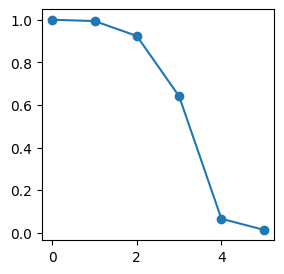

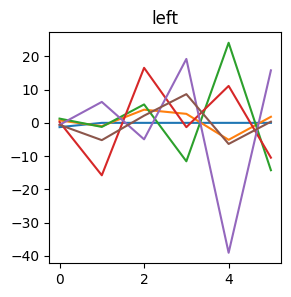

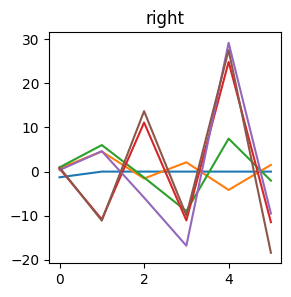

In [572]:
plt.figure(figsize=(3, 3))
plt.plot(S / S.max(),'o-')

plt.figure(figsize=(3, 3))
plt.plot(left_vec)
plt.title("left")

plt.figure(figsize=(3, 3))
plt.plot(right_vec)
plt.title("right")

Text(0.5, 1.0, 'proj left')

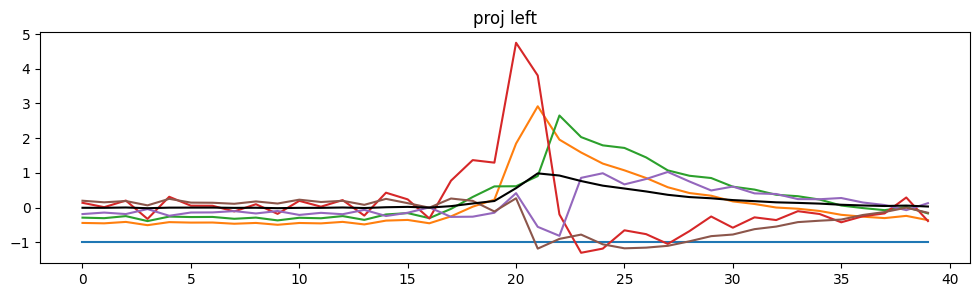

In [304]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_left.T[20:60])
plt.plot(X.ravel()[21:61], c="k")
plt.title("proj left")

Text(0.5, 1.0, 'proj right')

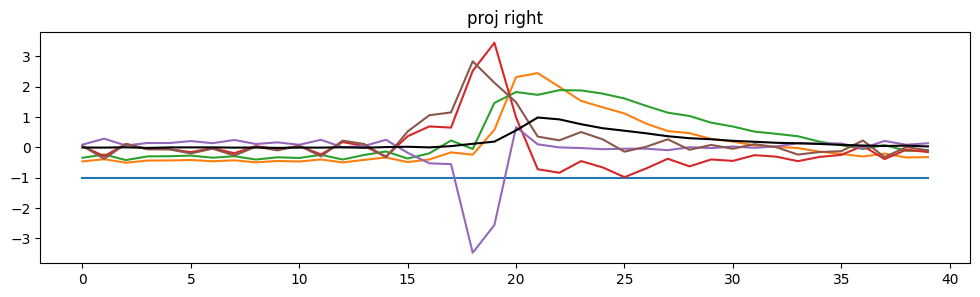

In [305]:
fig = plt.figure(figsize=(12, 3))
plt.plot(proj_right.T[20:60])
plt.plot(X.ravel()[21:61], c="k")
plt.title("proj right")

In [306]:
import numpy as np

In [307]:
pos = np.asarray([1, 2, 3])

In [308]:
pos.shape

(3,)

In [309]:
pos.size in [2, 3]

True

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
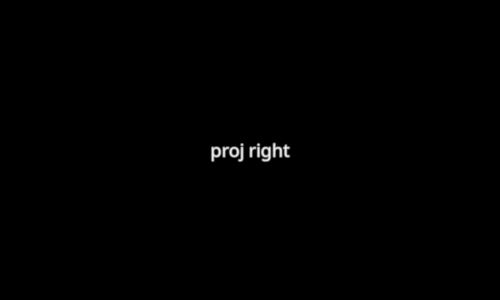

In [332]:
fig2 = fpl.Figure((3, 1), names=[["X", "proj left", "proj right"]], controller_ids="sync")

fig2["X"].add_line(X.ravel())

fig2["proj left"].add_line_collection(proj_left, cmap="tab20", alpha=0.5)
fig2["proj left"].add_line(X.ravel())
fig2["proj right"].add_line_collection(proj_right, cmap="tab20", alpha=0.5)
fig2["proj right"].add_line(X.ravel())

fig2.show(maintain_aspect=False)

In [333]:
from sklearn.cluster import KMeans

In [334]:
km = KMeans(3)

In [335]:
proj_left.shape

(6, 495)

In [336]:
proj_right.shape

(6, 495)

In [337]:
max_k = 4

In [338]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PowerTransformer

<Axes: >

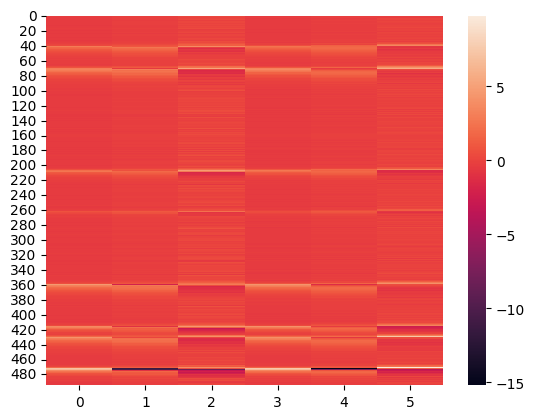

In [346]:
features = np.hstack([proj_left.T[:, 1:max_k], proj_right.T[:, 1:max_k]])
sns.heatmap(features)

In [347]:
labels = km.fit_predict(features)

In [348]:
labels.shape

(495,)

In [349]:
proj_left.shape

(6, 495)

In [350]:
proj_left.T.shape

(495, 6)

In [356]:
fig3 = fpl.Figure(size=(1800, 600))

# fig3[0, 0].add_line(X_clean.ravel()[:-3], colors="red", alpha=0.5)
lg = fig3[0, 0].add_line(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-5]]), cmap="tab10", cmap_transform=labels)
lg_s = fig3[0, 0].add_scatter(np.column_stack([np.arange(labels.shape[0]), X.ravel()[:-5]]), sizes=7, cmap="tab10", cmap_transform=labels)

fig4 = fpl.Figure((1, 2), cameras="3d", controller_types="orbit", names=["left", "right"])

sg_left = fig4[0, 0].add_scatter(proj_left.T[:, 1:4], sizes=7, cmap="tab10", cmap_transform=labels)
sg_right = fig4[0, 1].add_scatter(proj_right.T[:, 1:4], sizes=7, cmap="tab10", cmap_transform=labels)

# fig5 = fpl.Figure(cameras="3d", controller_types="orbit")

# sg_Q = fig5[0, 0].add_scatter(Qk, sizes=5, cmap="tab10", cmap_transform=labels)

for subplot in fig4:
    subplot.axes.intersection = (0, 0, 0)

selector = lg.add_linear_selector()

@selector.add_event_handler("selection")
def set_point(ev):
    ix = ev.get_selected_index()
    sg_left.cmap = "tab10"
    sg_right.cmap = "tab10"
    sg_Q.cmap = "tab10"

    sg_left.colors[ix] = "w"
    sg_right.colors[ix] = "w"
    sg_Q.colors[ix] = "w"

def scatter_click_handler(ev):
    ix = ev.pick_info["vertex_index"]

    sg_left.cmap = "tab10"
    sg_right.cmap = "tab10"
    sg_Q.cmap = "tab10"

    sg_left.colors[ix] = "w"
    sg_right.colors[ix] = "w"
    sg_Q.colors[ix] = "w"
    
    selector.selection = ix

sg_left.add_event_handler(scatter_click_handler, "click")
sg_right.add_event_handler(scatter_click_handler, "click")

VBox([fig3.show(maintain_aspect=False), fig4.show()])

RFBOutputContext()

RFBOutputContext()